# Pré-processamento: experimento com filtros

Nesta etapa comparamos filtros de suavização em uma série MRI, sem alterar os arquivos DICOM originais nem salvar um volume processado. A comparação ajuda a perceber tanto a redução de pequenas variações quanto a perda de detalhes nas bordas. Como não temos uma imagem perfeita sem ruído para servir de referência, um erro menor não significa, por si só, que o filtro recuperou a imagem verdadeira.

## Ideias matemáticas

- **Filtro Gaussiano:** substitui cada pixel por uma média ponderada dos pixels vizinhos. Pixels próximos recebem peso maior. Aumentar `sigma` suaviza mais, mas pode apagar detalhes e alargar bordas.
- **Filtro mediano:** substitui cada pixel pela mediana dos valores na vizinhança. Em uma janela 3 x 3, ordenamos nove intensidades e escolhemos a do meio. Valores extremos isolados têm menos influência, mas detalhes menores que a janela também podem desaparecer.

No ensaio 2D, usamos uma janela mediana 3 x 3 e `sigma = 1` pixel como parâmetros de comparação. No ensaio 3D, usamos o espaçamento físico `(z, y, x)` lido dos metadados DICOM para converter uma escala em milêmetros para voxels. Esses valores são experimentais, não parâmetros ótimos estabelecidos.

## Bibliotecas

- **OpenCV** (`cv2.GaussianBlur`, `cv2.medianBlur`): aplica os filtros ao corte 2D.
- **SciPy** (`scipy.ndimage.gaussian_filter`): aplica a gaussiana ao volume 3D.
- **NumPy** e **Matplotlib**: organizam e mostram os dados usados na exploração anterior.

## 1. Carregar a sequência original

A pasta é localizada a partir do diretório de trabalho atual do Jupyter ou de suas pastas ancestrais, para que o notebook também funcione quando aberto a partir da pasta que contém o projeto.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import cv2
import sys
from scipy import ndimage

current_dir = Path.cwd().resolve()
search_dirs = [current_dir, *current_dir.parents]
search_dirs.extend(parent / "reconstrucao-cranio" for parent in search_dirs.copy())
project_root = next(
    (folder for folder in search_dirs if (folder / "data" / "skull").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Não encontrei data/skull. "
        f"Diretório de trabalho atual do Jupyter: {current_dir}."
    )

src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)
from leitura import ler_dicom_volume

data_dir = project_root / "data" / "skull" / "0051" / "0051"
volume, voxel_spacing_zyx, image_files = ler_dicom_volume(data_dir)
if volume.ndim != 3 or volume.shape[0] != len(image_files):
    raise ValueError(
        f"Volume DICOM inesperado: dimensões {volume.shape}, tipo {volume.dtype}."
    )


## 2. Comparar filtros em um corte

Aplicamos os filtros ao corte central para que a comparação seja rápida e fácil de inspecionar. A gaussiana recebe `float32` para preservar valores fracionários durante o cálculo. Os três primeiros painéis usam a mesma escala de intensidade, baseada nos percentis do corte original. A diferença absoluta usa sua própria escala, pois seus valores são menores.

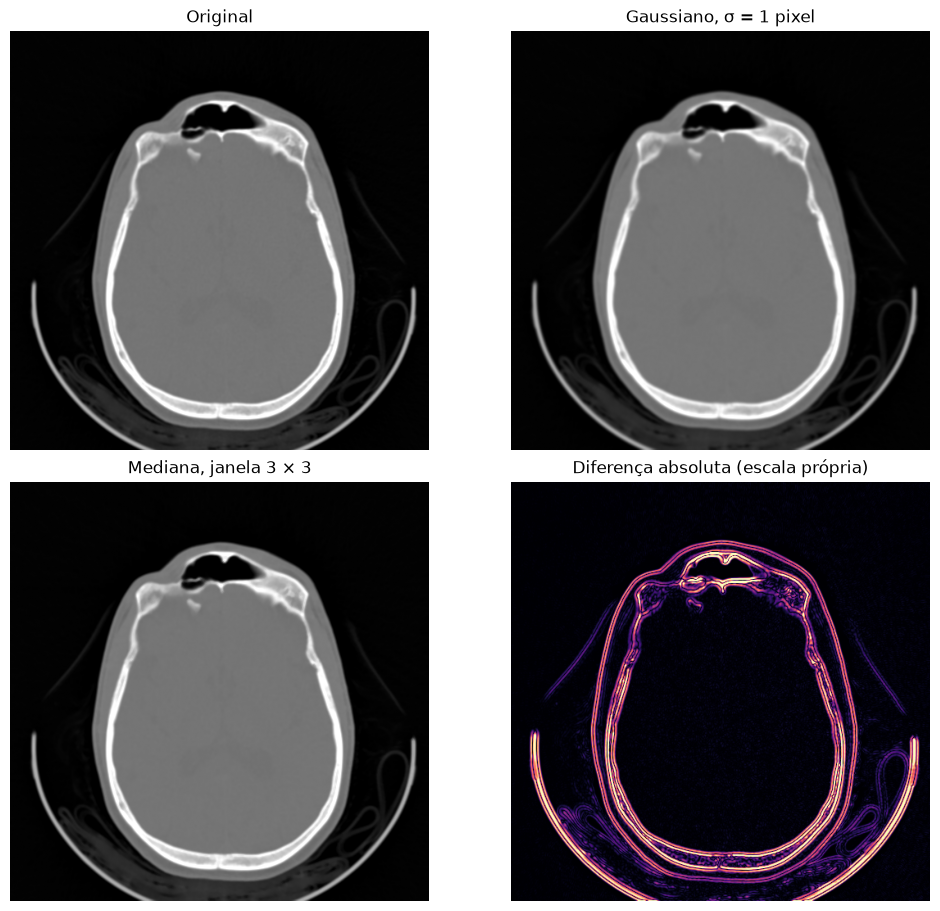

Corte central: 55 de 108
Tipo original: uint16; tipo filtrado Gaussiano: float32
Erro quadrático médio vs. original — Gaussiano: 624.72
Erro quadrático médio vs. original — mediana: 57.46


In [2]:
slice_index = volume.shape[0] // 2
slice_original = volume[slice_index]

gaussian_sigma_2d = 1.0
median_size_2d = 3
slice_gaussian = cv2.GaussianBlur(
    slice_original.astype(np.float32),
    ksize=(0, 0),
    sigmaX=gaussian_sigma_2d,
)
slice_median = cv2.medianBlur(slice_original, ksize=median_size_2d)

display_min, display_max = np.percentile(slice_original, [1, 99])
fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
gaussian_difference = np.abs(slice_original.astype(np.float32) - slice_gaussian)
median_difference = np.abs(slice_original.astype(np.float32) - slice_median)
panels = [
    (slice_original, "Original", "gray"),
    (slice_gaussian, "Gaussiano, σ = 1 pixel", "gray"),
    (slice_median, "Mediana, janela 3 × 3", "gray"),
    (gaussian_difference, "Diferença absoluta (escala própria)", "magma"),
]
for ax, (image, title, color_map) in zip(axes.flat, panels):
    if color_map == "gray":
        ax.imshow(image, cmap=color_map, vmin=display_min, vmax=display_max)
    else:
        ax.imshow(image, cmap=color_map, vmin=0, vmax=np.percentile(image, 99))
    ax.set_title(title)
    ax.axis("off")

plt.show()
print(f"Corte central: {slice_index + 1} de {len(image_files)}")
print(f"Tipo original: {slice_original.dtype}; tipo filtrado Gaussiano: {slice_gaussian.dtype}")
print(f"Erro quadrático médio vs. original — Gaussiano: {np.mean(gaussian_difference ** 2):.2f}")
print(f"Erro quadrático médio vs. original — mediana: {np.mean(median_difference ** 2):.2f}")

## 3. Considerar o espaçamento ao filtrar em 3D

O exemplo suaviza o volume completo com uma gaussiana 3D e mostra o corte central. O espaçamento ? lido dos metadados DICOM; convertemos `?` físico para voxels individualmente em cada eixo, evitando assumir que os três eixos tenham o mesmo espaçamento.

O resultado ? apenas experimental e permanece em memória. Os originais não são sobrescritos nem arquivos processados são gravados. Avalie visualmente se os detalhes e as bordas continuam distinguíveis.

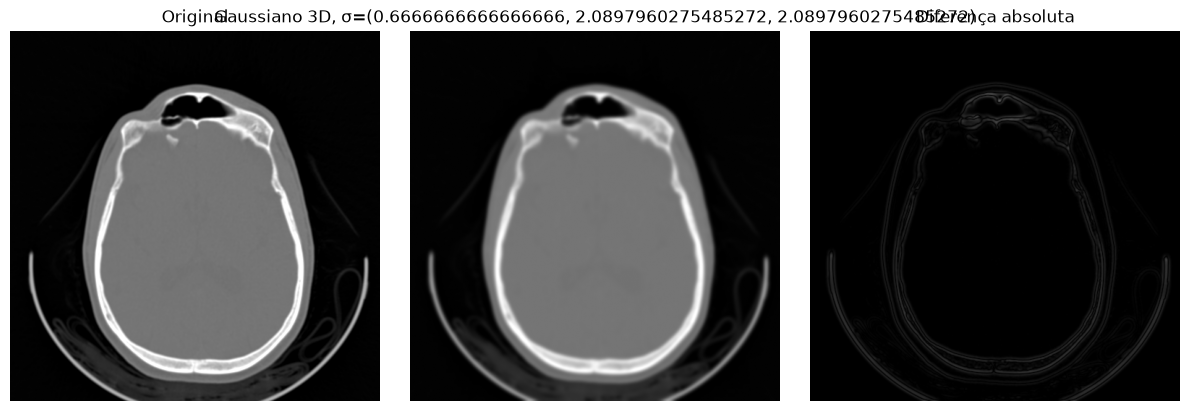

Sigma aplicado (z, y, x): (0.6666666666666666, 2.0897960275485272, 2.0897960275485272)
Volume filtrado: (108, 512, 512), tipo float32


In [3]:
sigma_physical_mm = 1.0
gaussian_sigma_zyx = tuple(
    sigma_physical_mm / spacing for spacing in voxel_spacing_zyx
)
volume_gaussian = ndimage.gaussian_filter(
    volume.astype(np.float32),
    sigma=gaussian_sigma_zyx,
    output=np.float32,
)
slice_gaussian_3d = volume_gaussian[slice_index]

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
images = [
    (slice_original, "Original"),
    (slice_gaussian_3d, f"Gaussiano 3D, σ={gaussian_sigma_zyx}"),
    (
        np.abs(slice_original.astype(np.float32) - slice_gaussian_3d),
        "Diferença absoluta",
    ),
]
for ax, (image, title) in zip(axes, images):
    ax.imshow(image, cmap="gray", vmin=display_min, vmax=display_max)
    ax.set_title(title)
    ax.axis("off")

plt.show()
print(f"Sigma aplicado (z, y, x): {gaussian_sigma_zyx}")
print(f"Volume filtrado: {volume_gaussian.shape}, tipo {volume_gaussian.dtype}")

## 4. Interpretar antes de avançar

Compare os detalhes, as bordas e as regiões da imagem nos resultados. Suavização excessiva pode apagar estruturas finas e alterar limites que seriam usados depois na segmentação. A diferença absoluta mostra onde os valores mudaram, mas não permite, sozinha, dizer que o resultado ? melhor.

Registre qual filtro parece mais adequado e se o `?` escolhido preserva os detalhes. Ainda não fazemos limiarização, operações morfolêgicas nem reconstrução 3D.